# PHÂN KHÚC KHÁCH HÀNG TRUNG TÂM THƯƠNG MẠI
## PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

### 1. Tổng quan dự án

Notebook này thực hiện quá trình phân tích khám phá dữ liệu (Exploratory Data Analysis - EDA) trên bộ dữ liệu khách hàng của trung tâm thương mại (Mall Customers).

Mục tiêu chính là tìm hiểu đặc điểm của khách hàng, xác định các xu hướng và khám phá mối quan hệ giữa những thuộc tính trong dữ liệu trước khi áp dụng thuật toán phân cụm K-Means.

### 2. Thông tin bộ dữ liệu

- Tên bộ dữ liệu: Mall_Customers.csv
- Số lượng quan sát: 200 khách hàng.
- Các thuộc tính:
  - CustomerID: Mã định danh khách hàng.
  - Gender: Giới tính.
  - Age: Độ tuổi.
  - Annual Income (k$): Thu nhập hằng năm (nghìn USD).
  - Spending Score (1-100): Điểm chi tiêu của khách hàng (từ 1 đến 100).

### 3. Mục tiêu phân tích

1. Khám phá cấu trúc và đặc điểm tổng quan của bộ dữ liệu.
2. Phân tích đặc điểm nhân khẩu học của khách hàng.
3. Khảo sát thu nhập hằng năm và hành vi chi tiêu.
4. Trực quan hóa mối quan hệ giữa các thuộc tính.
5. Nhận diện những đặc điểm và xu hướng có thể sử dụng để phân khúc khách hàng.
6. Chuẩn bị dữ liệu và cơ sở phân tích cho thuật toán phân cụm K-Means.

### 4. Phạm vi thực hiện

Quá trình phân tích tập trung vào việc khám phá dữ liệu gốc, kiểm tra chất lượng dữ liệu, thống kê mô tả và trực quan hóa dữ liệu.

Kết quả EDA sẽ được sử dụng làm cơ sở cho các bước tiền xử lý dữ liệu, xây dựng mô hình và đánh giá kết quả phân cụm khách hàng ở những giai đoạn tiếp theo.

In [13]:
# ==========================================
# IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
# ==========================================
# LOAD DATASET
# ==========================================

DATA_PATH = Path("../data/raw/Mall_Customers.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. KIỂM TRA CẤU TRÚC VÀ CHẤT LƯỢNG DỮ LIỆU

Ở bước này, chúng ta tiến hành kiểm tra cấu trúc tổng thể của bộ dữ liệu nhằm xác định kiểu dữ liệu của từng thuộc tính, số lượng giá trị bị thiếu và các dòng dữ liệu trùng lặp.

Các nội dung cần kiểm tra:

- Số lượng dòng và cột của bộ dữ liệu.
- Kiểu dữ liệu của từng thuộc tính.
- Số lượng giá trị bị thiếu.
- Số lượng bản ghi trùng lặp.
- Thống kê mô tả các thuộc tính.

In [15]:
# KIỂM TRA CẤU TRÚC DỮ LIỆU

print("THÔNG TIN TỔNG QUAN VỀ BỘ DỮ LIỆU")
print("=" * 50)

df.info()

print("\nSỐ LƯỢNG GIÁ TRỊ BỊ THIẾU")
print(df.isnull().sum())

print("\nSỐ LƯỢNG DÒNG DỮ LIỆU TRÙNG LẶP")
print(df.duplicated().sum())

print("\nTHỐNG KÊ MÔ TẢ DỮ LIỆU")
display(df.describe(include="all"))

THÔNG TIN TỔNG QUAN VỀ BỘ DỮ LIỆU
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

SỐ LƯỢNG GIÁ TRỊ BỊ THIẾU
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

SỐ LƯỢNG DÒNG DỮ LIỆU TRÙNG LẶP
0

THỐNG KÊ MÔ TẢ DỮ LIỆU


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


## 4. PHÂN TÍCH PHÂN PHỐI CÁC THUỘC TÍNH

Ở bước này, chúng ta sử dụng các biểu đồ trực quan để khảo sát đặc điểm phân phối của dữ liệu khách hàng.

Các nội dung phân tích bao gồm:

- Phân phối độ tuổi khách hàng.
- Phân phối thu nhập hàng năm.
- Phân phối điểm chi tiêu.
- Cơ cấu khách hàng theo giới tính.

Mục tiêu là nhận biết đặc điểm, xu hướng và sự phân bố của khách hàng trước khi tiến hành phân cụm bằng thuật toán K-Means.

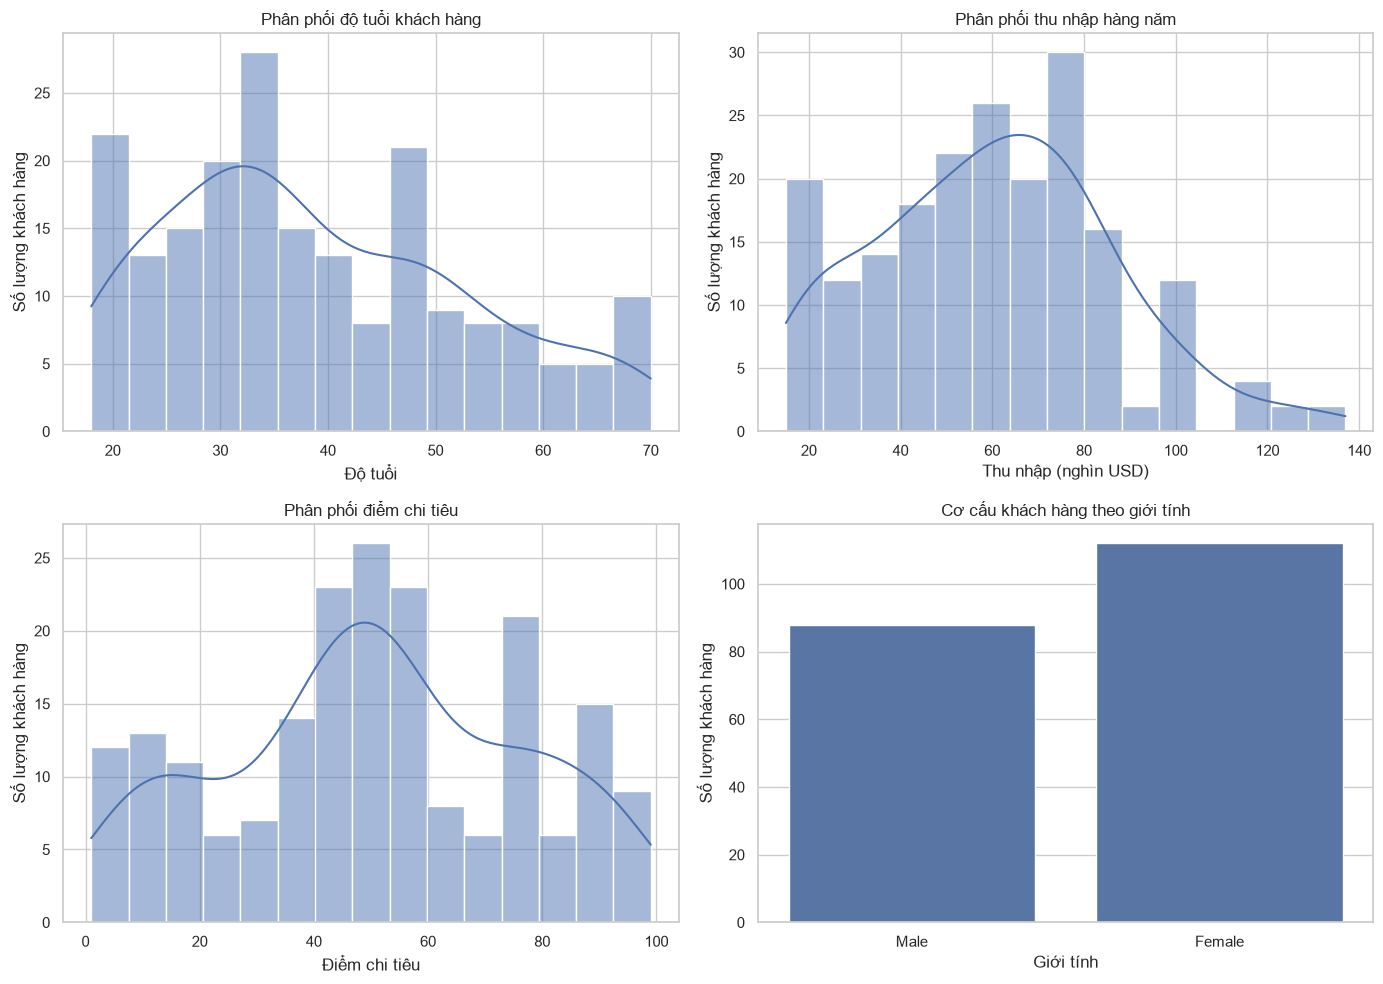

In [16]:
# PHÂN TÍCH PHÂN PHỐI CÁC THUỘC TÍNH

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Phân phối độ tuổi
sns.histplot(data=df, x="Age", bins=15, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Phân phối độ tuổi khách hàng")
axes[0, 0].set_xlabel("Độ tuổi")
axes[0, 0].set_ylabel("Số lượng khách hàng")

# 2. Phân phối thu nhập
sns.histplot(data=df, x="Annual Income (k$)", bins=15,
             kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Phân phối thu nhập hàng năm")
axes[0, 1].set_xlabel("Thu nhập (nghìn USD)")
axes[0, 1].set_ylabel("Số lượng khách hàng")

# 3. Phân phối điểm chi tiêu
sns.histplot(data=df, x="Spending Score (1-100)", bins=15,
             kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Phân phối điểm chi tiêu")
axes[1, 0].set_xlabel("Điểm chi tiêu")
axes[1, 0].set_ylabel("Số lượng khách hàng")

# 4. Phân phối giới tính
sns.countplot(data=df, x="Gender", ax=axes[1, 1])
axes[1, 1].set_title("Cơ cấu khách hàng theo giới tính")
axes[1, 1].set_xlabel("Giới tính")
axes[1, 1].set_ylabel("Số lượng khách hàng")

plt.tight_layout()
plt.show()

## 5. PHÂN TÍCH MỐI TƯƠNG QUAN GIỮA CÁC THUỘC TÍNH

Ở bước này, chúng ta tiến hành phân tích mối quan hệ giữa các thuộc tính số trong bộ dữ liệu.

Các nội dung thực hiện:

- Xây dựng ma trận tương quan giữa các thuộc tính.
- Sử dụng biểu đồ Heatmap để trực quan hóa mức độ tương quan.
- Phân tích mối quan hệ giữa thu nhập hàng năm và điểm chi tiêu của khách hàng.

Mục tiêu là xác định mức độ liên hệ giữa các thuộc tính, từ đó hiểu rõ hơn đặc điểm hành vi khách hàng và hỗ trợ lựa chọn dữ liệu đầu vào cho thuật toán phân cụm K-Means.

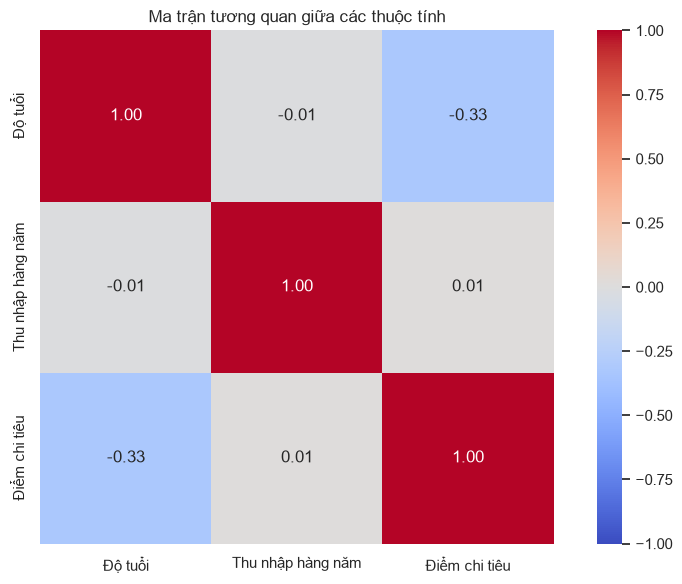

In [17]:
# 1. XÂY DỰNG MA TRẬN TƯƠNG QUAN

ten_cot = {
    "Age": "Độ tuổi",
    "Annual Income (k$)": "Thu nhập hàng năm",
    "Spending Score (1-100)": "Điểm chi tiêu"
}

du_lieu_so = df[list(ten_cot.keys())].rename(columns=ten_cot)

ma_tran_tuong_quan = du_lieu_so.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    ma_tran_tuong_quan,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Ma trận tương quan giữa các thuộc tính")
plt.tight_layout()
plt.show()

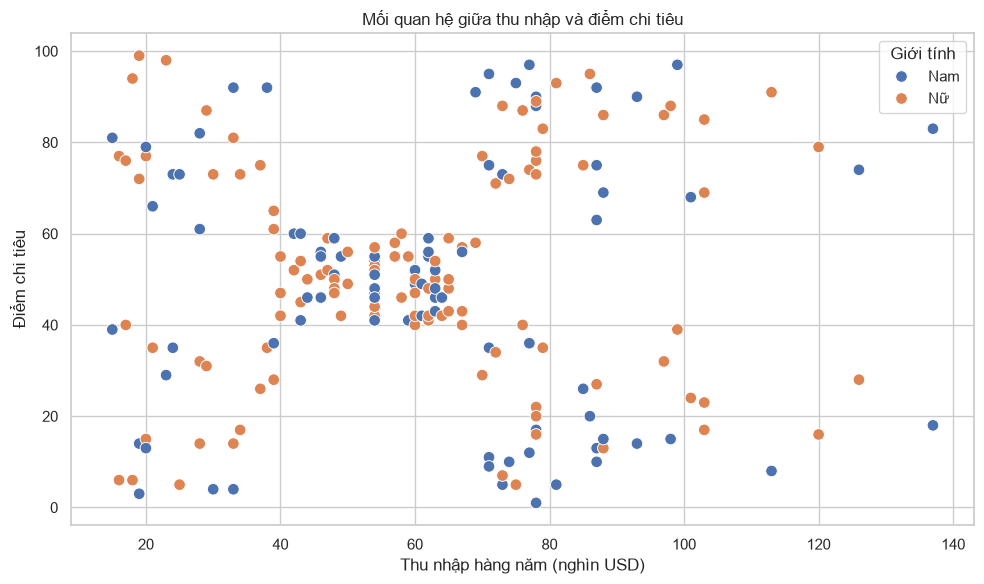

In [18]:
# 2. PHÂN TÍCH MỐI QUAN HỆ GIỮA THU NHẬP VÀ CHI TIÊU

du_lieu_ve = df.copy()

du_lieu_ve["Giới tính"] = du_lieu_ve["Gender"].map({
    "Male": "Nam",
    "Female": "Nữ"
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=du_lieu_ve,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Giới tính",
    s=70
)

plt.title("Mối quan hệ giữa thu nhập và điểm chi tiêu")
plt.xlabel("Thu nhập hàng năm (nghìn USD)")
plt.ylabel("Điểm chi tiêu")
plt.legend(title="Giới tính")

plt.tight_layout()
plt.show()

## 6. NHẬN XÉT KẾT QUẢ PHÂN TÍCH TƯƠNG QUAN

### 6.1. Nhận xét ma trận tương quan

Qua ma trận tương quan, có thể rút ra một số nhận xét:

- Độ tuổi và thu nhập hàng năm có hệ số tương quan -0.01, cho thấy gần như không có mối quan hệ tuyến tính.
- Độ tuổi và điểm chi tiêu có hệ số tương quan -0.33, thể hiện mối tương quan âm yếu. Khách hàng lớn tuổi có xu hướng có điểm chi tiêu thấp hơn.
- Thu nhập hàng năm và điểm chi tiêu có hệ số tương quan 0.01, cho thấy gần như không có mối quan hệ tuyến tính giữa hai thuộc tính.

### 6.2. Nhận xét biểu đồ phân tán

Biểu đồ phân tán cho thấy khách hàng có mức thu nhập tương tự nhau vẫn có hành vi chi tiêu rất khác nhau.

Hai nhóm khách hàng nam và nữ có sự phân bố chồng lấn tương đối lớn. Vì vậy, không thể chỉ dựa vào giới tính hoặc thu nhập để xác định hành vi chi tiêu của khách hàng.

### 6.3. Kết luận

Kết quả phân tích cho thấy các thuộc tính trong bộ dữ liệu không có mối tương quan tuyến tính mạnh với nhau.

Điều này cho thấy cần xem xét đồng thời nhiều thuộc tính để nhận diện đặc điểm và hành vi của từng nhóm khách hàng.

Thuật toán K-Means được lựa chọn để phân nhóm khách hàng dựa trên sự tương đồng của nhiều thuộc tính, thay vì chỉ dựa vào một biến riêng lẻ.